# 3 · PM feature decisions: BeanBox's "perfect" churn model

**What you practise (from the feature-engineering lecture):**
- The **snapshot rule**: a feature may only use information that exists *before* the moment we predict.
- **Hunting a leak** in a "too good" result.
- The **four tests** every feature must pass: *available · same definition · allowed · useful*.
- One honest **recipe** (`Pipeline`) and fair comparisons with **cross-validation**.
- Turning domain knowledge into **yes/no flags** that a simple model can use.
- **Unknown categories** in production, a **feature spec**, and a recommendation.

## ☕ The case: BeanBox

**BeanBox** sends freshly roasted coffee beans to subscribers every month. About **1 in 4 subscribers cancels** in a given month.

**Nora**, Head of Retention, has a team that can **call 100 subscribers per month** with a personal offer (a free bag, a pause option). She asks:

*"On the 1st of every month, can a model tell us **which 100 subscribers to call**, the ones most likely to cancel this month?"*

- **Snapshot:** we score everyone on the morning of **1 November**.
- **Label:** `cancelled` = 1 if the subscriber cancelled **between 1 and 30 November**.
- **Kai**, the data scientist, has just sent his first model…

> 📌 The data is **synthetic** (made for this course) but realistic: 2,000 subscribers, 14 columns. Same ideas as TeamFlow, different product. Tomorrow you work on TeamFlow's real data.

> **How this notebook works**
> - Run the cells **from top to bottom** with `Shift + Enter`.
> - ▶️ **Run** cells work as they are.
> - ✏️ **Your turn** cells contain `___` (three underscores). Replace each `___` with your answer, then run the cell.
> - ✅ **Check** cells tell you whether you got it right. If a check fails, read the hint, fix the cell above and run both again.
> - 🧠 **Think** cells ask a PM question. Double-click the answer cell below it and write 1–3 sentences.
> - If you see `NameError: name '___' is not defined`, a blank is still empty.
> - Stuck? The `solutions/` folder has the same notebook, solved.

## Step 0 · Load the tools and the data

In [1]:
# ▶️ Run: libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

subscribers = pd.read_csv("../data/beanbox_subscribers.csv")
subscribers.head()

,subscriber_id,months_subscribed,plan,bags_per_month,signup_channel,country,app_opens_last_4w,deliveries_skipped_90d,support_contacts_90d,avg_bag_rating,lifetime_spend_eur,days_since_last_order,exit_survey_done,cancelled
0,BB-10001,9,starter,1,google_ads,AT,7,0,0,NaN,100.25,17,0,0
1,BB-10002,7,classic,2,instagram,DE,2,0,1,NaN,183.60,1,0,0
2,BB-10003,6,classic,3,instagram,DE,1,0,0,NaN,251.34,64,1,1
3,BB-10004,10,starter,1,friend_referral,NL,8,0,0,NaN,103.87,10,0,0
4,BB-10005,6,classic,2,friend_referral,NL,2,0,0,3.0,172.31,20,0,0


| column | meaning (all as of the 1 Nov snapshot, **unless stated**) |
|---|---|
| `subscriber_id` | ID |
| `months_subscribed` | months since sign-up |
| `plan` | `starter` < `classic` < `barista` (bigger, pricier beans) |
| `bags_per_month` | bags in each delivery |
| `signup_channel` | instagram, google_ads, friend_referral, podcast (empty = tracking blocked) |
| `country` | DE, AT, CH, NL |
| `app_opens_last_4w` | app opens in the 4 weeks before 1 Nov |
| `deliveries_skipped_90d` | deliveries skipped in the 90 days before 1 Nov |
| `support_contacts_90d` | support contacts in the 90 days before 1 Nov |
| `avg_bag_rating` | average star rating the subscriber gave their bags (empty = never rated) |
| `lifetime_spend_eur` | total spent since sign-up |
| `days_since_last_order` | days since the last order, **computed by Kai's export script on 30 Nov** |
| `exit_survey_done` | 1 = the subscriber filled in the exit survey |
| **`cancelled`** | **target**: 1 = cancelled between 1 and 30 Nov |

In [2]:
# ✏️ Your turn: what share of subscribers cancelled in November?
# Hint: `cancelled` is 0/1, so its average IS the share of 1s.
cancel_share = subscribers["cancelled"].mean()
print("Cancelled in November:", round(cancel_share, 3))

Cancelled in November: 0.242


In [3]:
# ✅ Check
assert abs(cancel_share - 0.242) < 0.001, "Use .mean()"
print("✅ Correct: 24.2% cancelled, about 1 in 4. If Nora's team called 100 RANDOM subscribers, they'd reach about 24 cancellers.")

✅ Correct: 24.2% cancelled, about 1 in 4. If Nora's team called 100 RANDOM subscribers, they'd reach about 24 cancellers.


## Step 1 · Split first (the test set is next month's subscribers)

In [4]:
# ▶️ Run: 75% to learn from, 25% kept aside as the final exam (stratified: same cancel share in both)
X = subscribers.drop(columns="cancelled")
y = subscribers["cancelled"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("train:", len(X_train), "| test:", len(X_test), "of which cancelled:", y_test.sum())

train: 1500 | test: 500 of which cancelled: 121


## Step 2 · Kai's report

Kai: *"I used **every** column. Look at this!"*

The cell below defines Kai's **recipe** (fill gaps → scale numbers, one-hot the words, plan in its real order, then logistic regression). **Just run it**: you'll look inside in Step 5.

In [5]:
# ▶️ Run: the recipe helper (you don't need to read the code yet)
def build_model(number_columns):
    numbers = Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    words = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("one_hot", OneHotEncoder(handle_unknown="ignore"))])
    plan = Pipeline([("order", OrdinalEncoder(categories=[["starter", "classic", "barista"]])),
                     ("scale", StandardScaler())])
    prep = ColumnTransformer([("numbers", numbers, list(number_columns)),
                              ("words", words, ["signup_channel", "country"]),
                              ("plan", plan, ["plan"])])          # every other column is left out
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])


def cv_auc(number_columns, X_data=X_train):
    """5-fold cross-validation AUC on the TRAINING data only (the 'rehearsal exams')."""
    return cross_val_score(build_model(number_columns), X_data, y_train, cv=5, scoring="roc_auc").mean()


all_numbers = ["months_subscribed", "bags_per_month", "app_opens_last_4w", "deliveries_skipped_90d",
               "support_contacts_90d", "avg_bag_rating", "lifetime_spend_eur",
               "days_since_last_order", "exit_survey_done"]
print("Recipe ready.")

Recipe ready.


In [6]:
# ▶️ Run: Kai's model, trained on the training rows and scored ONCE on the test rows
kai_model = build_model(all_numbers).fit(X_train, y_train)
kai_auc = roc_auc_score(y_test, kai_model.predict_proba(X_test)[:, 1])
print(f"📈 Kai's test AUC: {kai_auc:.3f}")

📈 Kai's test AUC: 1.000


AUC 1.00 means **every** canceller got a higher risk score than **every** subscriber who stayed. For human behaviour like cancelling a subscription, that almost never happens honestly.

🚩 **Red flag #4: a feature that's too good.** A score that looks too good is a *question*, not a celebration.

## Step 3 · Hunt the leak

PM question #1: **"Which single column helps most?"** The cell below scores each number column **on its own** (AUC of that one column, training data only).

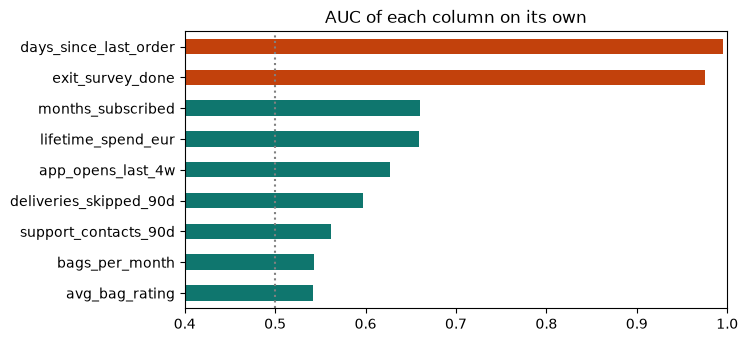

days_since_last_order     0.995
exit_survey_done          0.975
months_subscribed         0.661
lifetime_spend_eur        0.660
app_opens_last_4w         0.627
deliveries_skipped_90d    0.597
support_contacts_90d      0.561
bags_per_month            0.543
avg_bag_rating            0.542
dtype: float64

In [7]:
# ▶️ Run: how well does each column ALONE rank cancellers above stayers? (0.5 = coin flip, 1.0 = perfect)
def one_column_auc(column):
    values = X_train[column].fillna(X_train[column].median())
    auc = roc_auc_score(y_train, values)
    return max(auc, 1 - auc)            # direction doesn't matter here

alone = pd.Series({c: one_column_auc(c) for c in all_numbers}).sort_values()
alone.plot.barh(figsize=(7, 3.6), color=["#c2410c" if v > 0.9 else "#0f766e" for v in alone])
plt.axvline(0.5, color="grey", ls=":"); plt.xlim(0.4, 1.0); plt.title("AUC of each column on its own")
plt.show()
alone.round(3).sort_values(ascending=False)

In [8]:
# ✏️ Your turn: which TWO columns are suspicious? (write the column names)
suspicious = ["days_since_last_order", "exit_survey_done"]

In [9]:
# ✅ Check
assert sorted(c.strip() for c in suspicious) == ["days_since_last_order", "exit_survey_done"], \
    "Look for the two bars far above all the others."
print("✅ Correct: each of them ALONE is almost perfect. Real churn signals are never that clean.")

✅ Correct: each of them ALONE is almost perfect. Real churn signals are never that clean.


🧠 **Think:** PM question #2: **when is each of these two columns filled in?** Would we have them on the morning of 1 November? Which of the two leaks is *sneakier*, and why?

**✍️ Sample answer:** `exit_survey_done` only exists for people who already cancelled: it is filled in *during* cancellation, after 1 Nov. It's the answer copied into the question (target leakage). `days_since_last_order` is sneakier: it *sounds* like a normal history feature, but Kai's script counted up to the **export day (30 Nov)**. Someone who cancelled on 10 Nov has 20+ days without an order *because* they cancelled. Computed as of 1 Nov, the same column would be fine. Same name, wrong date: temporal leakage.

In [10]:
# ✏️ Your turn: remove both leaks from the number columns
honest_numbers = [c for c in all_numbers if c not in suspicious]
honest_cv = cv_auc(honest_numbers)
print("Columns kept:", honest_numbers)
print(f"Honest cross-validated AUC: {honest_cv:.3f}")

Columns kept:

 ['months_subscribed', 'bags_per_month', 'app_opens_last_4w', 'deliveries_skipped_90d', 'support_contacts_90d', 'avg_bag_rating', 'lifetime_spend_eur']
Honest cross-validated AUC: 0.706


In [11]:
# ✅ Check
assert "exit_survey_done" not in honest_numbers and "days_since_last_order" not in honest_numbers
assert 0.68 < honest_cv < 0.74
print(f"✅ From 1.00 to {honest_cv:.2f}. Less exciting, but this is what the model can really do on 1 November.")

✅ From 1.00 to 0.71. Less exciting, but this is what the model can really do on 1 November.


## Step 4 · The four tests (Activity A, BeanBox edition)

Before any column goes in, it must pass **four tests, in this order**:

| test | question |
|---|---|
| ⏱ **Available?** | Does it exist *before* the prediction moment, every time we score? |
| 📏 **Same definition?** | Is it computed the same way in training and in production (window, date, unit)? |
| ⚖️ **Allowed?** | Are we permitted and justified to use it (documented purpose, fair, what users would expect)? |
| 📈 **Useful?** | Does it improve results on validation data, and is it worth maintaining? |

Why this order? **A leak always looks useful.** Check usefulness last.

Give each candidate a verdict: `"use"` (as is), `"fix"` (define or transform first), `"leak"` (future information) or `"dont"` (not allowed / not justified).

In [12]:
# ✏️ Your turn: your verdict for each candidate column
verdicts = {
    "months_subscribed":     "use",   # months since sign-up, as of 1 Nov
    "app_opens_last_4w":     "use",   # window is written down: 4 weeks before 1 Nov
    "lifetime_spend_eur":    "fix",   # an all-time total: what happens to it as people stay longer?
    "avg_bag_rating":        "fix",   # empty for more than half of the subscribers
    "days_since_last_order": "fix",   # counted up to 30 Nov by Kai's export script
    "exit_survey_done":      "leak",  # filled in while cancelling
    "country":               "fix",   # DE, AT, CH, NL … and Belgium launches next month
    "gender":                "dont",  # not in the data yet. Kai asks: "Shall I pull it from the CRM?"
}

In [13]:
# ✅ Check: compare with the answer key (some cards are grey zones: two answers accepted)
key = {
    "months_subscribed": ({"use"}, "Known on 1 Nov, clearly defined."),
    "app_opens_last_4w": ({"use"}, "Window is fixed (4 weeks before the snapshot)."),
    "lifetime_spend_eur": ({"fix"}, "Grows with tenure by definition. Use spend per month, or spend in the last 90 days."),
    "avg_bag_rating": ({"fix"}, "Missing ≠ 0. Fill with the median AND keep a 'never rated' flag."),
    "days_since_last_order": ({"fix", "leak"}, "Leaks as computed (30 Nov). Fix: count up to the snapshot date."),
    "exit_survey_done": ({"leak"}, "Exists only after cancelling."),
    "country": ({"fix", "use"}, "One-hot, plan for unknown countries, check results per country (fairness)."),
    "gender": ({"dont"}, "No demonstrated need, fairness + privacy questions. Exception only with documented purpose + legal review."),
}
assert set(verdicts) == set(key) and all(v in {"use", "fix", "leak", "dont"} for v in verdicts.values()), \
    "Use only 'use', 'fix', 'leak' or 'dont' for every card."
matches = 0
for column, (accepted, reason) in key.items():
    ok = verdicts[column] in accepted
    matches += ok
    print(f"{'✅' if ok else '🤔'} {column:22s} you: {verdicts[column]:5s} key: {'/'.join(sorted(accepted)):9s} {reason}")
print(f"\n{matches} of 8 match the key. Disagree with a 🤔? Good: write down your argument for the stand-up.")

✅ months_subscribed      you: use   key: use       Known on 1 Nov, clearly defined.
✅ app_opens_last_4w      you: use   key: use       Window is fixed (4 weeks before the snapshot).
✅ lifetime_spend_eur     you: fix   key: fix       Grows with tenure by definition. Use spend per month, or spend in the last 90 days.
✅ avg_bag_rating         you: fix   key: fix       Missing ≠ 0. Fill with the median AND keep a 'never rated' flag.
✅ days_since_last_order  you: fix   key: fix/leak  Leaks as computed (30 Nov). Fix: count up to the snapshot date.
✅ exit_survey_done       you: leak  key: leak      Exists only after cancelling.
✅ country                you: fix   key: fix/use   One-hot, plan for unknown countries, check results per country (fairness).
✅ gender                 you: dont  key: dont      No demonstrated need, fairness + privacy questions. Exception only with documented purpose + legal review.

8 of 8 match the key. Disagree with a 🤔? Good: write down your argument for the stand-

From now on we use only columns that pass the tests **today**. `lifetime_spend_eur` waits until its definition is fixed (it's mostly "tenure in disguise" anyway).

In [14]:
# ▶️ Run: our honest starting point
model_numbers = [c for c in honest_numbers if c != "lifetime_spend_eur"]
base_cv = cv_auc(model_numbers)
print("Number columns:", model_numbers)
print(f"Cross-validated AUC: {base_cv:.3f}")

Number columns: ['months_subscribed', 'bags_per_month', 'app_opens_last_4w', 'deliveries_skipped_90d', 'support_contacts_90d', 'avg_bag_rating']
Cross-validated AUC: 0.708


## Step 5 · Look inside the recipe

The same recipe runs in training, in cross-validation, and later in production. Click the boxes in the diagram to open them.

In [15]:
# ▶️ Run: scikit-learn draws the recipe
build_model(model_numbers)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numbers', ...), ('words', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If 

In [16]:
# ✏️ Your turn: read the recipe
branch_for_country = "words"        # which branch ("numbers", "words" or "plan") handles `country`?
rating_fill_strategy = "median"     # how are the gaps in avg_bag_rating filled?
rating_gets_a_flag = True           # does the recipe also add a "was missing" column? (True / False)

In [17]:
# ✅ Check
assert branch_for_country == "words" and rating_fill_strategy == "median" and rating_gets_a_flag is True, \
    "Look at the helper in Step 2: 'words' gets signup_channel and country; numbers use median + add_indicator=True."
print("✅ Correct: 'never rated' becomes its own 0/1 column. Missing ≠ zero, and missing can be a signal.")

✅ Correct: 'never rated' becomes its own 0/1 column. Missing ≠ zero, and missing can be a signal.


🧠 **Think:** why is it important that the fill → scale → encode steps live **inside** the pipeline, rather than being done once on the whole table before cross-validation?

**✍️ Sample answer:** Inside the pipeline, every cross-validation fold re-learns the medians, scales and categories from its own training part, so the validation part never shapes the preparation (no train–test contamination). And the exact same fitted object is saved and used in production, so new subscribers are prepared with the training numbers (no training–serving skew, no hand-copied medians).

## Step 6 · Domain knowledge → yes/no flags

Logistic regression gives each column **one straight-line effect**: "each extra month lowers the risk by the same amount". But churn often has **jumps**. Let's look at the training data.

In [18]:
# ▶️ Run: cancel rate by months subscribed (TRAINING rows only)
train = X_train.assign(cancelled=y_train)
months_groups = pd.cut(train["months_subscribed"], [0, 1, 2, 3, 4, 5, 6, 9, 12, 24, 48])
train.groupby(months_groups, observed=True)["cancelled"].agg(cancel_rate="mean", subscribers="size").round(3)

,cancel_rate,subscribers
months_subscribed,,
"(0, 1]",0.640,25
"(1, 2]",0.604,101
"(2, 3]",0.552,116
"(3, 4]",0.212,118
"(4, 5]",0.189,95
"(5, 6]",0.152,92
"(6, 9]",0.171,252
"(9, 12]",0.178,185
"(12, 24]",0.179,364


In [19]:
# ✏️ Your turn: up to how many months is a subscriber "new" (clearly higher risk)?
new_cutoff = 3

In [20]:
# ▶️ Run: cancel rate by app opens in the last 4 weeks (TRAINING rows only)
opens_groups = pd.cut(train["app_opens_last_4w"], [-1, 0, 1, 2, 3, 5, 10, 40])
train.groupby(opens_groups, observed=True)["cancelled"].agg(cancel_rate="mean", subscribers="size").round(3)

,cancel_rate,subscribers
app_opens_last_4w,,
"(-1, 0]",0.419,117
"(0, 1]",0.516,161
"(1, 2]",0.189,185
"(2, 3]",0.161,137
"(3, 5]",0.231,308
"(5, 10]",0.184,412
"(10, 40]",0.156,180


In [21]:
# ✏️ Your turn: up to how many app opens is a subscriber "inactive"?
inactive_cutoff = 1

In [22]:
# ✅ Check
assert new_cutoff == 3, "Where does the cancel rate drop sharply? Between 3 and 4 months."
assert inactive_cutoff == 1, "Where does the cancel rate drop sharply? Between 1 and 2 opens."
print("✅ Correct: ≤ 3 months and ≤ 1 app open are where the risk jumps.")

✅ Correct: ≤ 3 months and ≤ 1 app open are where the risk jumps.


In [23]:
# ▶️ Run: add the two flags (fixed rules, all inputs as of 1 Nov) and compare with cross-validation
def add_flags(table):
    return table.assign(is_new=(table["months_subscribed"] <= new_cutoff).astype(int),
                        is_inactive=(table["app_opens_last_4w"] <= inactive_cutoff).astype(int))

X_train_flags, X_test_flags = add_flags(X_train), add_flags(X_test)

In [24]:
# ✏️ Your turn: add the flag columns to the number columns
cv_new = cv_auc(model_numbers + ["is_new"], X_train_flags)
cv_both = cv_auc(model_numbers + ["is_new", "is_inactive"], X_train_flags)
print(f"honest model, no flags ... {base_cv:.3f}")
print(f"+ is_new ................. {cv_new:.3f}")
print(f"+ is_new + is_inactive ... {cv_both:.3f}")

honest model, no flags ... 0.708
+ is_new ................. 0.762
+ is_new + is_inactive ... 0.790


In [25]:
# ✅ Check
assert cv_both > cv_new > base_cv, "Add 'is_new' in the first line and 'is_inactive' in the second."
print(f"✅ Same model, same settings, two extra yes/no columns: {base_cv:.3f} → {cv_both:.3f}.")

✅ Same model, same settings, two extra yes/no columns: 0.708 → 0.790.


> 🔍 **Honesty note:** we picked the cut-offs by looking at *all* training rows, and then cross-validated on those same rows. Strictly, the cut-offs should be re-learned inside each fold. In the lecture we checked this on TeamFlow and the cut-offs came out identical. Most importantly: **the test set has not been touched for any choice.**

🧠 **Think:** the model already has `months_subscribed`. Why does an extra `is_new` column help?

**✍️ Sample answer:** `months_subscribed` gives the model a **slope**: a little less risk every month. The real pattern is a **switch**: high risk in months 1–3, then a sharp drop. A straight line can only tilt; the 0/1 flag hands the model the jump directly, so one weight can say "being new adds a lot of risk". We keep the original column too, so nothing is lost.

## Step 7 · The final exam: test set, used once

Now, and only now, we score the 500 held-out subscribers. Nora doesn't care about AUC: she cares about **how many cancellers her team reaches with 100 calls**.

In [26]:
# ▶️ Run: fit both versions on ALL training rows, score the test rows once
before = build_model(model_numbers).fit(X_train_flags, y_train)
after = build_model(model_numbers + ["is_new", "is_inactive"]).fit(X_train_flags, y_train)

results = {}
for name, model in [("without flags", before), ("with flags", after)]:
    scores = model.predict_proba(X_test_flags)[:, 1]
    top_100 = np.argsort(-scores)[:100]                     # the 100 highest-risk subscribers
    results[name] = {"test AUC": round(roc_auc_score(y_test, scores), 3),
                     "cancellers in top 100": int(y_test.to_numpy()[top_100].sum())}
results = pd.DataFrame(results).T.astype({"cancellers in top 100": int})
results

,test AUC,cancellers in top 100
without flags,0.735,50
with flags,0.797,59


In [27]:
# ✏️ Your turn: what share of Nora's 100 calls (with flags) reaches someone who would really cancel?
caught_with_flags = results.loc["with flags", "cancellers in top 100"]
call_precision = caught_with_flags / 100
print(f"{call_precision:.0%} of the calls reach a real canceller (random calling: about 24%).")

59% of the calls reach a real canceller (random calling: about 24%).


In [28]:
# ✅ Check
assert abs(call_precision - caught_with_flags / 100) < 1e-9, "Divide by the number of calls: 100."
print(f"✅ Correct. Same team, same 100 calls: {results.iloc[0, 1]} → {caught_with_flags} cancellers reached.")

✅ Correct. Same team, same 100 calls: 50 → 59 cancellers reached.


In [29]:
# ▶️ Run: can Nora understand the model? The biggest weights (number columns are scaled, word columns are 0/1)
names = after.named_steps["prep"].get_feature_names_out()
weights = pd.Series(after.named_steps["model"].coef_[0], index=names)
weights.index = weights.index.str.replace("numbers__|words__|plan__", "", regex=True)
weights.sort_values(key=abs, ascending=False).head(8).round(2)

is_new                             0.78
is_inactive                        0.57
signup_channel_friend_referral    -0.46
deliveries_skipped_90d             0.36
missingindicator_avg_bag_rating    0.33
support_contacts_90d               0.31
signup_channel_instagram           0.28
avg_bag_rating                    -0.21
dtype: float64

🧠 **Think:** write the model's story for Nora in **one sentence** she could repeat to her team.

**✍️ Sample answer:** "New subscribers (first 3 months) and subscribers who barely open the app are the most likely to cancel; skipping deliveries and contacting support add risk, while long-time, engaged subscribers are the safest." (Check the weights above: `is_new` and `is_inactive` are among the largest, and both point to higher risk.)

## Step 8 · Production surprise: Belgium 🇧🇪

On 1 December the model scores the next batch. Marketing launched BeanBox in **Belgium** last week, so some subscribers have `country = "BE"`, a value the encoder has never seen.

In [30]:
# ▶️ Run: six subscribers from the December batch
december = pd.DataFrame({
    "subscriber_id": ["BB-20001", "BB-20002", "BB-20003", "BB-20004", "BB-20005", "BB-20006"],
    "months_subscribed": [1, 14, 2, 7, 1, 30], "plan": ["starter", "classic", "starter", "barista", "classic", "classic"],
    "bags_per_month": [1, 2, 1, 3, 2, 2], "signup_channel": ["instagram", "friend_referral", np.nan, "podcast", "instagram", "google_ads"],
    "country": ["BE", "DE", "BE", "AT", "DE", "CH"], "app_opens_last_4w": [0, 9, 1, 6, 3, 12],
    "deliveries_skipped_90d": [0, 0, 1, 0, 0, 1], "support_contacts_90d": [1, 0, 2, 0, 0, 0],
    "avg_bag_rating": [np.nan, 4.5, np.nan, 4.0, np.nan, 5.0],
})
december_scores = after.predict_proba(add_flags(december))[:, 1]
december.assign(risk=december_scores.round(2))[["subscriber_id", "country", "months_subscribed", "app_opens_last_4w", "risk"]]

,subscriber_id,country,months_subscribed,app_opens_last_4w,risk
0,BB-20001,BE,1,0,0.91
1,BB-20002,DE,14,9,0.02
2,BB-20003,BE,2,1,0.95
3,BB-20004,AT,7,6,0.05
4,BB-20005,DE,1,3,0.52
5,BB-20006,CH,30,12,0.03


No error: the recipe uses `OneHotEncoder(handle_unknown="ignore")`, so a Belgian subscriber gets **0 in every country column** ("none of the countries I know"). Scoring continues, but nobody knows how good the scores are for Belgium. That has to be **visible**.

In [31]:
# ✏️ Your turn: a tiny monitoring check. What SHARE of December's subscribers has an unknown country?
known_countries = set(X_train["country"].unique())
unknown_share = (~december["country"].isin(known_countries)).mean()
print(f"Unknown country: {unknown_share:.0%} of the batch")

Unknown country: 33% of the batch


In [32]:
# ✅ Check
assert abs(unknown_share - 2 / 6) < 1e-9, "True/False values: their .mean() is the share of True."
print("✅ Correct: 2 of 6 (33%). In a real batch you'd log this number every day and alert above a threshold.")

✅ Correct: 2 of 6 (33%). In a real batch you'd log this number every day and alert above a threshold.


🧠 **Think (PM decision):** Belgium will grow fast. Should the model **fail loudly** on unknown countries, or **keep scoring and alert**? Who gets the alert, and when do we retrain?

**✍️ Sample answer:** Keep scoring (Nora's call list must arrive on the 1st), but monitor: log the share of unknown countries each day, alert the model owner and the Belgium launch team above an agreed threshold (e.g. 5%), and retrain once there are enough Belgian subscribers with known outcomes. Optionally fail if unknowns exceed a much larger share (something is broken). Best of all: Marketing tells the data team *before* the next launch.

## Step 9 · Your PM artefact: a feature spec

A feature spec is a short, written agreement about one input: a **user story for data**. Each line answers one of the four tests. Write the spec for **`is_inactive`**.

**✍️ Sample spec:**

| line | sample answer |
|---|---|
| **Name** | `is_inactive` |
| **Definition** | 1 if the subscriber opened the app **at most once** in the **4 weeks (28 days) before the snapshot date** (00:00 UTC on the 1st), else 0 |
| **Source · owner** | App event log · Mobile team (product questions: the Engagement PM) |
| **Available when?** | Nightly batch ready at 05:00 on the 1st, before the scoring job at 07:00 |
| **Missing rule** | No app installed / no events → `app_opens_last_4w = 0` is **correct** here (0 opens is a real value), but add an `app_installed` flag so "never installed" and "stopped opening" can be told apart |
| **Allowed?** | Purpose (churn prevention) and legal basis documented; covered in the privacy notice; privacy review done; data minimised: store the count, not the raw event log |
| **Monitor** | Share of `is_inactive = 1` per month; alert if it jumps by more than 20% (could be a logging outage, not real churn) |

## Step 10 · Your recommendation for Nora

🧠 **Think:** ship, pilot or improve? Write 3–4 sentences: what the model does, how well (in Nora's terms), the biggest risk, and the next step.

**✍️ Sample answer:** **Pilot.** With the two flags, the model's top 100 reaches about 6 in 10 real cancellers, compared with about 2–3 in 10 for random calls, and the story is simple (new + inactive = risky). Kai's 1.00 model must not ship: its two best columns are leaks that don't exist on the 1st. Biggest risks: definitions drifting in production (the 4-week window, the snapshot date) and new markets like Belgium. Next step: a one-month pilot with a control group (half of the top 100 called, half not) to measure whether the calls actually *prevent* cancellations, plus the feature specs and monitoring above.

## ✅ Check your understanding

1. A model reports AUC 1.00. What are the three questions you ask first?
2. Why did we compare the flags with **cross-validation** and not with the test set?
3. What does a pipeline guarantee, and what can it *not* guarantee?

**Your answers to 1–3:**

**✍️ Sample answer:** (1) Which single column helps most, and what's left without it? When is each column filled in? Would we have it on the morning we predict? (2) Every choice made by looking at the test score turns the test into another training set and makes the final number too optimistic. Cross-validation on training data is the place to choose; the test set is used once, at the end. (3) It guarantees the same preparation steps with the same learned numbers in training, cross-validation and production. It can't guarantee that the raw input still *means* the same thing upstream (a changed window, a logging bug). That's what the feature spec and monitoring are for.

### 🎉 Well done! Tomorrow: TeamFlow's real data, your own churn model, and a ship-or-not recommendation for Maya.